# Paper 5.1 — periodic Fourier model: accuracy against the Koopman semigroup and cost

Reversible periodic diffusion with generator $\mathcal A_\beta f=\partial_x\big((1+\beta\cos x)\partial_x f\big)$, $\beta=1/2$,
invariant law $dx/(2\pi)$, exponential dictionary $\{e_k:|k|\le K\}$ (orthonormal, so $G=I$), horizon $T=1$, and the
observable with Fourier coefficients $\hat f_k\propto(1+k^2)^{-7/2}$ (normalized to $\|f\|=1$).

In the orthonormal basis $\mathcal A_\beta$ is the exact tridiagonal matrix
$\mathcal A_\beta e_k=-k^2e_k-\tfrac{\beta}{2}(k^2+k)e_{k+1}-\tfrac{\beta}{2}(k^2-k)e_{k-1}$, so the population operators
$A_K$, $B_K=\Pi_K\mathcal A^2|_{\mathcal V_K}$ and the reference $\mathcal K^Tf$ (exact exponential of the cutoff-256 truncation)
need no quadrature.

This notebook reproduces

* Table 2: population errors $\|(Q_{K,\Delta t})^n\Pi_Kf-\mathcal K^Tf\|$ of SDMD-1, SDMD-R, SDMD-2 and the Galerkin error
  for $\Delta t\approx1.5/\|A_K\|$ (Theorem 4.3), the contraction check $\|Q^{[2]}_{K,\Delta t}\|=1$ (Theorem 4.3),
  the growth of $\Theta_K\Delta t$, and the closed form $\Theta_K=\beta^2(K^2+K)^2/4$ (Example 4.5); the Galerkin column
  for $K\ge32$ is recomputed in 60-digit arithmetic (`mpmath`, reference cutoff 96);
* Table 3 and Figure 1: the same errors with empirical matrices from $m$ i.i.d. uniform samples (seed 20260507),
  the perturbations of $\widehat{\mathbf A}$ and $\widehat{\mathbf B}$, and the computing times for the matrices of
  SDMD-1/SDMD-R ($\widehat G_m,\widehat H_m$) and SDMD-2 ($\widehat G_m,\widehat H_m,\widehat J_m$),
  with $\mathcal A\psi$ and $\mathcal A^2\psi$ evaluated by the generic derivative formulas (Corollary 4.4, Table 1).

Runtime: about two minutes for the sampled part and a few minutes for the 60-digit cell.

In [1]:
import time
import numpy as np

SEED = 20260507
beta = 0.5
T = 1.0


def fit_slope(x, y):
    """Least-squares slope of log y against log x."""
    return float(np.polyfit(np.log(np.asarray(x, float)), np.log(np.asarray(y, float)), 1)[0])


def fourier_generator(M, beta=beta):
    """Matrix of A_beta on span{e_k : |k| <= M} in the orthonormal basis (exact, tridiagonal)."""
    kk = np.arange(-M, M + 1)
    n = kk.size
    Am = np.zeros((n, n))
    for i, k in enumerate(kk):
        Am[i, i] = -k**2
        if i + 1 < n:
            Am[i + 1, i] = -beta / 2 * (k**2 + k)
        if i - 1 >= 0:
            Am[i - 1, i] = -beta / 2 * (k**2 - k)
    return Am, kk


def galerkin_operators(K, beta=beta):
    """A_K = Pi_K A|_{V_K} and B_K = Pi_K A^2|_{V_K}; the truncation M = K + 2 makes both exact."""
    Am, kk = fourier_generator(K + 2, beta)
    idx = np.where(np.abs(kk) <= K)[0]
    return Am[np.ix_(idx, idx)], (Am @ Am)[np.ix_(idx, idx)]


def expm_sym(A, t):
    d, V = np.linalg.eigh(A)
    return (V * np.exp(t * d)) @ V.T


def step_for(AK):
    """dt ~ 1.5/||A_K||, rounded so that T/dt is an integer."""
    nA = np.linalg.norm(AK, 2)
    n = int(round(T / (1.5 / nA)))
    return T / n, n


def one_step_maps(A, B, dt):
    """SDMD-1, SDMD-R, SDMD-2 one-step matrices built from (possibly empirical) A and B."""
    I = np.eye(A.shape[0])
    Q1 = I + dt * A
    QR = I + dt * A + 0.5 * dt**2 * (A @ A)
    Q2 = I + dt * A + 0.5 * dt**2 * B
    return Q1, QR, Q2


# reference solution K^T f on the cutoff-256 truncation (truncation error far below the errors reported)
M = 256
Am, kk = fourier_generator(M)
fhat = (1.0 + kk.astype(float)**2) ** (-3.5)
fhat = fhat / np.linalg.norm(fhat)
uT = expm_sym(Am, T) @ fhat


def embed(v, idx):
    out = np.zeros(fhat.size, dtype=complex)
    out[idx] = v
    return out


def fixed_horizon_errors(AK, BK, dt, n, idx):
    """Errors ||Q^n Pi_K f - K^T f|| of the three schemes (complex matrices allowed)."""
    fK = fhat[idx]
    return [float(np.linalg.norm(embed(np.linalg.matrix_power(Q, n) @ fK, idx) - uT))
            for Q in one_step_maps(AK, BK, dt)]

## Table 2: population errors, contraction check, and the closed form of $\Theta_K$

In [2]:
maxrel = 0.0
for K in range(1, 65):
    AK, BK = galerkin_operators(K)
    th = np.linalg.norm(BK - AK @ AK, 2)
    maxrel = max(maxrel, abs(th - beta**2 / 4 * (K**2 + K)**2) / th)
print(f"Example 4.5: max relative deviation of Theta_K from beta^2 (K^2+K)^2 / 4 over 1 <= K <= 64: {maxrel:.1e}\n")

print("Table 2: population errors ||(Q_K)^n Pi_K f - K^T f||, dt ~ 1.5/||A_K|| (Galerkin column in double precision)")
print("   K    N      dt      n  dt|A_K|  Theta_K*dt  ||Q2||   Galerkin    SDMD-1     SDMD-R     SDMD-2")
table2 = []
for K in [2, 4, 8, 16, 32, 64]:
    idx = np.where(np.abs(kk) <= K)[0]
    AK, BK = galerkin_operators(K)
    dt, n = step_for(AK)
    th = np.linalg.norm(BK - AK @ AK, 2)
    _, _, Q2 = one_step_maps(AK, BK, dt)
    eG = float(np.linalg.norm(embed(expm_sym(AK, T) @ fhat[idx], idx) - uT))
    e1, eR, e2 = fixed_horizon_errors(AK, BK, dt, n, idx)
    table2.append((K, dt, n, eG, e1, eR, e2))
    print(f"{K:4d} {2*K+1:4d}  {dt:.2e} {n:5d}   {dt*np.linalg.norm(AK, 2):5.2f}   {th*dt:8.2f}   {np.linalg.norm(Q2, 2):.4f}"
          f"  {eG:.2e}   {e1:.2e}   {eR:.2e}   {e2:.2e}")
Ks = [r[0] for r in table2 if r[0] >= 4]
for j, name in zip(range(4, 7), ["SDMD-1", "SDMD-R", "SDMD-2"]):
    print(f"slope in K over K = 16..64, {name}: {fit_slope([r[0] for r in table2[-3:]], [r[j] for r in table2[-3:]]):.2f}")

Example 4.5: max relative deviation of Theta_K from beta^2 (K^2+K)^2 / 4 over 1 <= K <= 64: 0.0e+00

Table 2: population errors ||(Q_K)^n Pi_K f - K^T f||, dt ~ 1.5/||A_K|| (Galerkin column in double precision)
   K    N      dt      n  dt|A_K|  Theta_K*dt  ||Q2||   Galerkin    SDMD-1     SDMD-R     SDMD-2
   2    5  3.33e-01     3    1.36       0.75   1.0000  1.65e-03   8.33e-03   4.90e-03   4.79e-03
   4    9  9.09e-02    11    1.56       2.27   1.0000  7.39e-05   1.95e-03   1.14e-04   1.24e-04
   8   17  2.04e-02    49    1.49       6.61   1.0000  2.14e-07   4.26e-04   3.61e-06   3.61e-06
  16   33  4.78e-03   209    1.50      22.12   1.0000  3.01e-12   9.94e-05   1.93e-07   1.93e-07
  32   65  1.13e-03   888    1.50      78.49   1.0000  8.16e-22   2.34e-05   1.06e-08   1.06e-08
  64  129  2.69e-04  3715    1.50     291.14   1.0000  1.80e-37   5.58e-06   6.05e-10   6.05e-10
slope in K over K = 16..64, SDMD-1: -2.08
slope in K over K = 16..64, SDMD-R: -4.16
slope in K over K = 16..64

### Galerkin column of Table 2 in 60-digit arithmetic

For $K\ge32$ the Galerkin error $\|e^{TA_K}\Pi_Kf-\mathcal K^Tf\|$ lies below double-precision resolution, so this
column is recomputed with `mpmath`. $\mathcal A_\beta e_0=0$, and $\mathcal A_\beta$ maps $\mathrm{span}\{e_k:k\ge1\}$ and
$\mathrm{span}\{e_k:k\le-1\}$ into themselves; $\hat f$ is even in $k$ and $\mathcal A_\beta$ commutes with $k\to-k$, so the
error is $\sqrt2$ times the error on the positive-$k$ block, whose matrix is symmetric tridiagonal with entries
$(k,k)=-k^2$ and $(k,k+1)=-(\beta/2)(k^2+k)$. The reference uses cutoff 96 (checked against cutoff 112).

In [3]:
import mpmath as mp

mp.mp.dps = 60
mp_beta, mp_T = mp.mpf(beta), mp.mpf(T)
mp_norm = mp.mpf(np.linalg.norm((1.0 + kk.astype(float)**2) ** (-3.5)))   # normalization of fhat above


def mp_block(M):
    A = mp.zeros(M, M)
    for i in range(M):
        k = i + 1
        A[i, i] = -k**2
        if i + 1 < M:
            A[i + 1, i] = A[i, i + 1] = -(mp_beta / 2) * (k**2 + k)
    return A


def mp_galerkin_solution(M):
    d, V = mp.eigsy(mp_block(M))
    f = mp.matrix([(1 + mp.mpf(k)**2) ** mp.mpf(-3.5) / mp_norm for k in range(1, M + 1)])
    c = V.T * f
    return V * mp.matrix([mp.exp(mp_T * d[j]) * c[j] for j in range(M)])


def mp_error(u, v):
    n = max(u.rows, v.rows)
    s = mp.fsum(((u[i] if i < u.rows else 0) - (v[i] if i < v.rows else 0))**2 for i in range(n))
    return mp.sqrt(2 * s)


u_ref = mp_galerkin_solution(96)
print(f"truncation check of the reference: ||u_96 - u_112|| = {mp.nstr(mp_error(u_ref, mp_galerkin_solution(112)), 3)}")
print("Table 2, Galerkin column in 60-digit arithmetic [double precision above]")
dp = {r[0]: r[3] for r in table2}
for K in [4, 8, 16, 32, 64]:
    print(f"{K:4d}   {mp.nstr(mp_error(mp_galerkin_solution(K), u_ref), 3):>9s}   [{dp[K]:.2e}]")

truncation check of the reference: ||u_96 - u_112|| = 9.18e-59
Table 2, Galerkin column in 60-digit arithmetic [double precision above]
   4     7.39e-5   [7.39e-05]
   8     2.14e-7   [2.14e-07]
  16    3.01e-12   [3.01e-12]


  32    1.09e-21   [8.16e-22]


  64    2.75e-40   [1.80e-37]


## Table 3: empirical matrices, perturbations, and computing cost

The arrays are evaluated by the generic formulas (with $\varpi\equiv1$, so $b=a'$)
$\mathcal A\psi=a\psi''+a'\psi'$ and $\mathcal A^2\psi=a g''+a' g'$ with $g=\mathcal A\psi$,
$g'=a\psi'''+2a'\psi''+a''\psi'$, $g''=a\psi''''+3a'\psi'''+3a''\psi''+a'''\psi'$,
so that the timed matrix computation includes the evaluation of the arrays $\mathcal A\Psi$ and $\mathcal A^2\Psi$ of Table 1.

In [4]:
def coefficient_derivatives(x, order):
    a = 1.0 + beta * np.cos(x)
    ds = [a, -beta * np.sin(x), -beta * np.cos(x), beta * np.sin(x)]
    return ds[: order + 1]


def dictionary_derivatives(kk_idx, x, order):
    """psi, psi', ..., psi^{(order)} as (N, m) arrays for psi_k = e^{ikx}."""
    E = np.exp(1j * np.outer(kk_idx, x))
    ik = 1j * kk_idx.astype(float)
    return [E * (ik**p)[:, None] for p in range(order + 1)]


def assemble_first(kk_idx, x):
    """SDMD-1 / SDMD-R: evaluations of psi and A psi, matrices G, H, and A = G^{-1} H."""
    m = x.size
    psi, d1, d2 = dictionary_derivatives(kk_idx, x, 2)
    a, a1 = coefficient_derivatives(x, 1)
    Apsi = a * d2 + a1 * d1
    Gh = (np.conj(psi) @ psi.T) / m
    Hh = (np.conj(psi) @ Apsi.T) / m
    return Gh, Hh, np.linalg.solve(Gh, Hh)


def assemble_second(kk_idx, x):
    """SDMD-2: evaluations of psi, A psi, A^2 psi, matrices G, H, J, and A = G^{-1} H, B = G^{-1} J."""
    m = x.size
    psi, d1, d2, d3, d4 = dictionary_derivatives(kk_idx, x, 4)
    a, a1, a2, a3 = coefficient_derivatives(x, 3)
    Apsi = a * d2 + a1 * d1
    g1 = a * d3 + 2 * a1 * d2 + a2 * d1
    g2 = a * d4 + 3 * a1 * d3 + 3 * a2 * d2 + a3 * d1
    A2psi = a * g2 + a1 * g1
    Gh = (np.conj(psi) @ psi.T) / m
    Hh = (np.conj(psi) @ Apsi.T) / m
    Jh = (np.conj(psi) @ A2psi.T) / m
    return Gh, Hh, Jh, np.linalg.solve(Gh, Hh), np.linalg.solve(Gh, Jh)


def timed(fn, *args, reps=3):
    best, out = np.inf, None
    for _ in range(reps):
        t0 = time.perf_counter()
        out = fn(*args)
        best = min(best, time.perf_counter() - t0)
    return best, out


def propagate(Q, n, fK):
    return np.linalg.matrix_power(Q, n) @ fK


# consistency check of the generic evaluation against the closed-form tridiagonal action
rng = np.random.default_rng(SEED)
xchk, kchk = rng.uniform(0.0, 2.0 * np.pi, 7), np.arange(-6, 7)
_psi, _d1, _d2, _d3, _d4 = dictionary_derivatives(kchk, xchk, 4)
_a, _a1, _a2, _a3 = coefficient_derivatives(xchk, 3)
A1chk = _a * _d2 + _a1 * _d1
A2chk = _a * (_a * _d4 + 3 * _a1 * _d3 + 3 * _a2 * _d2 + _a3 * _d1) + _a1 * (_a * _d3 + 2 * _a1 * _d2 + _a2 * _d1)
Amchk, kkchk = fourier_generator(8)
Echk = np.exp(1j * np.outer(kkchk, xchk))
idxchk = np.where(np.abs(kkchk) <= 6)[0]
print("generic A psi, A^2 psi versus closed form: max deviations "
      f"{np.max(np.abs(A1chk - Amchk[:, idxchk].T @ Echk)):.1e}, {np.max(np.abs(A2chk - (Amchk @ Amchk)[:, idxchk].T @ Echk)):.1e}")

rng = np.random.default_rng(SEED)
REPS = 10
print(f"\nTable 3: sampled errors (means over {REPS} repetitions), perturbations, and computing times (best of 3, seconds)")
print("   K     m        SDMD-1     SDMD-R     SDMD-2   | |Ahat-A|   |Bhat-B|  | t_mat(1,R)  t_mat(2)   t_step(1) t_step(R) t_step(2)")
table3 = []
for K, m in [(4, 10_000), (8, 10_000), (16, 10_000), (32, 10_000), (64, 10_000), (8, 1_000), (8, 100_000), (16, 100_000), (32, 100_000)]:
    idx = np.where(np.abs(kk) <= K)[0]
    kk_idx = np.arange(-K, K + 1)
    AK, BK = galerkin_operators(K)
    dt, n = step_for(AK)
    fK = fhat[idx]
    errs, devA, devB = np.zeros((REPS, 3)), [], []
    for r in range(REPS):
        x = rng.uniform(0.0, 2.0 * np.pi, m)
        _, _, _, Ah, Bh = assemble_second(kk_idx, x)
        errs[r] = fixed_horizon_errors(Ah, Bh, dt, n, idx)
        devA.append(np.linalg.norm(Ah - AK, 2))
        devB.append(np.linalg.norm(Bh - BK, 2))
    x = rng.uniform(0.0, 2.0 * np.pi, m)            # one further sample for the timings
    t1, (_, _, Ah) = timed(assemble_first, kk_idx, x)
    t2, (_, _, _, Ah2, Bh) = timed(assemble_second, kk_idx, x)
    assert np.allclose(Ah, Ah2)
    Q1, QR, Q2 = one_step_maps(Ah, Bh, dt)
    ts = [timed(propagate, Q, n, fK)[0] for Q in (Q1, QR, Q2)]
    mean = errs.mean(axis=0)
    table3.append(dict(K=K, m=m, dt=dt, n=n, err=mean, devA=np.mean(devA), devB=np.mean(devB), t1=t1, t2=t2, ts=ts))
    print(f"{K:4d} {m:7d}   {mean[0]:.2e}   {mean[1]:.2e}   {mean[2]:.2e}  | {np.mean(devA):.2e}  {np.mean(devB):.2e}  |"
          f"  {t1:8.2g}  {t2:8.2g}   {ts[0]:7.2g}  {ts[1]:7.2g}  {ts[2]:7.2g}")
rowsK = [r for r in table3 if r["m"] == 10_000]
rowsm = [r for r in table3 if r["K"] == 8]
print(f"\nfitted exponent in K at m = 1e4: {fit_slope([r['K'] for r in rowsK], [r['devA'] for r in rowsK]):.2f} for |Ahat - A_K|,"
      f" {fit_slope([r['K'] for r in rowsK], [r['devB'] for r in rowsK]):.2f} for |Bhat - B_K|   (bounds K^3 and K^5; variance proxy K^{5/2})")
print(f"fitted exponent in m at K = 8:   {fit_slope([r['m'] for r in rowsm], [r['devA'] for r in rowsm]):.2f} for |Ahat - A_K|,"
      f" {fit_slope([r['m'] for r in rowsm], [r['devB'] for r in rowsm]):.2f} for |Bhat - B_K|   (predicted -1/2)")
print("matrix computing time ratio SDMD-2 / SDMD-1:", [round(r["t2"] / r["t1"], 2) for r in table3])
import json
json.dump([dict(K=r["K"], m=r["m"], err=list(map(float, r["err"])), t1=r["t1"], t2=r["t2"], ts=list(map(float, r["ts"]))) for r in table3],
          open("results_fourier_1d.json", "w"), indent=1)
print("wrote results_fourier_1d.json (data for the left panel of Figure 1)")

generic A psi, A^2 psi versus closed form: max deviations 6.6e-14, 5.5e-12

Table 3: sampled errors (means over 10 repetitions), perturbations, and computing times (best of 3, seconds)
   K     m        SDMD-1     SDMD-R     SDMD-2   | |Ahat-A|   |Bhat-B|  | t_mat(1,R)  t_mat(2)   t_step(1) t_step(R) t_step(2)


   4   10000   1.95e-03   1.14e-04   1.24e-04  | 1.71e-01  7.18e+00  |    0.0065     0.011   1.5e-05  1.4e-05  1.4e-05


   8   10000   4.26e-04   3.60e-06   3.61e-06  | 8.95e-01  1.32e+02  |     0.011      0.02   2.8e-05  2.7e-05  2.7e-05


  16   10000   9.94e-05   1.93e-07   1.93e-07  | 4.39e+00  2.42e+03  |     0.024     0.043   0.00011   0.0001   0.0001


  32   10000   2.34e-05   1.06e-08   1.06e-08  | 2.33e+01  5.02e+04  |     0.082      0.12   0.00075  0.00077  0.00078


  64   10000   5.58e-06   6.05e-10   6.05e-10  | 1.27e+02  1.08e+06  |      0.14      0.27     0.006   0.0061   0.0082
   8    1000   4.26e-04   3.57e-06   3.60e-06  | 2.59e+00  3.81e+02  |    0.0019    0.0027   4.6e-05  4.4e-05  4.6e-05


   8  100000   4.26e-04   3.61e-06   3.61e-06  | 2.34e-01  3.38e+01  |      0.17       0.3     5e-05  5.1e-05  4.8e-05


  16  100000   9.94e-05   1.93e-07   1.93e-07  | 1.36e+00  7.57e+02  |      0.34      0.67   0.00015   0.0001   0.0001


  32  100000   2.34e-05   1.06e-08   1.06e-08  | 7.33e+00  1.56e+04  |      0.79       1.4     0.001    0.001    0.001

fitted exponent in K at m = 1e4: 2.38 for |Ahat - A_K|, 4.30 for |Bhat - B_K|   (bounds K^3 and K^5; variance proxy K^2.5)
fitted exponent in m at K = 8:   -0.52 for |Ahat - A_K|, -0.53 for |Bhat - B_K|   (predicted -1/2)
matrix computing time ratio SDMD-2 / SDMD-1: [1.66, 1.72, 1.76, 1.53, 1.94, 1.47, 1.8, 1.97, 1.76]
wrote results_fourier_1d.json (data for the left panel of Figure 1)


## Figure 1: error against computing time ($m=10^4$), left panel; the right panel uses `results_torus2d.json` from `5_1_fourier_torus2d.ipynb`

saved /home/claude/sdmd_revision/nbrun2/figures/fig_work_precision.pdf


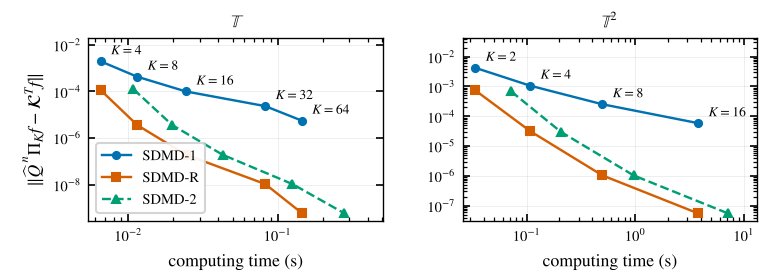

In [1]:
import io
import json
import shutil
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display

FIG_DIR = Path.cwd().parent / "figures"  # the folder that main.tex loads from
TEXTWIDTH_PT = 370.38374  # \textwidth of main.tex (siamart220329)
COLORS = {"blue": "#0072B2", "red": "#D55E00", "green": "#009E73"}
plt.rcParams.update({
    "text.usetex": True, "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif", "font.serif": ["Computer Modern Roman"],
    "font.size": 8.5, "axes.labelsize": 8.5, "legend.fontsize": 7.0, "axes.titlesize": 8.5,
    "xtick.labelsize": 7.0, "ytick.labelsize": 7.0,
    "lines.linewidth": 1.15, "lines.markersize": 3.4, "axes.linewidth": 0.65,
    "axes.grid": True, "grid.alpha": 0.22, "grid.linewidth": 0.45,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "legend.framealpha": 0.92, "legend.edgecolor": "0.82", "pdf.fonttype": 42,
})
if not (shutil.which("latex") and shutil.which("dvipng")):  # LaTeX text rendering needs both
    plt.rcParams.update({"text.usetex": False, "mathtext.fontset": "stix", "font.family": "STIXGeneral"})

# left panel: this notebook (Table 3, m = 1e4); right panel: 5_1_fourier_torus2d.ipynb (Table 4, m = 1e4),
# which writes results_torus2d.json into this directory; without that file only the left panel is drawn
d1 = [r for r in json.load(open(Path.cwd() / "results_fourier_1d.json")) if r["m"] == 10_000]  # written by the Table 3 cell
panels = [dict(title=r"$\mathbb{T}$", K=[r["K"] for r in d1],
               t=[[r["t1"] + r["ts"][0] for r in d1], [r["t1"] + r["ts"][1] for r in d1], [r["t2"] + r["ts"][2] for r in d1]],
               err=[[r["err"][j] for r in d1] for j in range(3)])]
twod = Path.cwd() / "results_torus2d.json"
if twod.exists():
    d2 = json.load(open(twod))
    panels.append(dict(title=r"$\mathbb{T}^2$", K=[r["K"] for r in d2],
                       t=[[r["t_1R"] + r["ts"]["sdmd1"] for r in d2], [r["t_1R"] + r["ts"]["sdmdR"] for r in d2], [r["t_2"] + r["ts"]["sdmd2"] for r in d2]],
                       err=[[r["err"][s] for r in d2] for s in ("sdmd1", "sdmdR", "sdmd2")]))
else:
    print("results_torus2d.json not found: drawing the one-dimensional panel only")

width = TEXTWIDTH_PT / 72.27
fig, axes = plt.subplots(1, len(panels), figsize=(width, 0.36 * width), squeeze=False)
for ax, P in zip(axes[0], panels):
    ax.loglog(P["t"][0], P["err"][0], marker="o", color=COLORS["blue"], label="SDMD-1")
    ax.loglog(P["t"][1], P["err"][1], marker="s", color=COLORS["red"], label="SDMD-R")
    ax.loglog(P["t"][2], P["err"][2], marker="^", color=COLORS["green"], label="SDMD-2", linestyle="--")
    for K, x, y in zip(P["K"], P["t"][0], P["err"][0]):
        ax.annotate(rf"$K={K}$", (x, y), textcoords="offset points", xytext=(5, 3), ha="left", fontsize=6.5)
    ax.set_xlim(right=max(max(P["t"][2]), 3.5 * max(P["t"][0])))  # room for the last K label
    ax.set_ylim(top=10 * max(P["err"][0]))
    ax.set_xlabel("computing time (s)")
    ax.set_title(P["title"], pad=5)
axes[0][0].set_ylabel(r"$\|\widehat{Q}^{\,n}\Pi_K f-\mathcal{K}^T f\|$")
axes[0][0].legend(loc="lower left", frameon=True)
fig.subplots_adjust(left=0.115, right=0.985, top=0.86, bottom=0.20, wspace=0.27)
FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / "fig_work_precision.pdf", format="pdf")
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=150)
plt.close(fig)
print("saved", FIG_DIR / "fig_work_precision.pdf")
display(Image(data=buf.getvalue()))
